TRANSFORMADAS DE LAPLACE

Exemplo 1: Exponencial decrescente
x1(t) = exp(-2*t)*Heaviside(t)
X1(s) = 1/(s + 2)

Exemplo 2: Senoide amortecida
x2(t) = exp(-t)*cos(4*t)*Heaviside(t)
X2(s) = (s + 1)/((s + 1)**2 + 16)

Exemplo 3: Senoide não amortecida
x3(t) = cos(5*t)*Heaviside(t)
X3(s) = s/(s**2 + 25)

POLOS DAS TRANSFORMADAS
Exemplo 1: [-2]
Exemplo 2: []
Exemplo 3: []


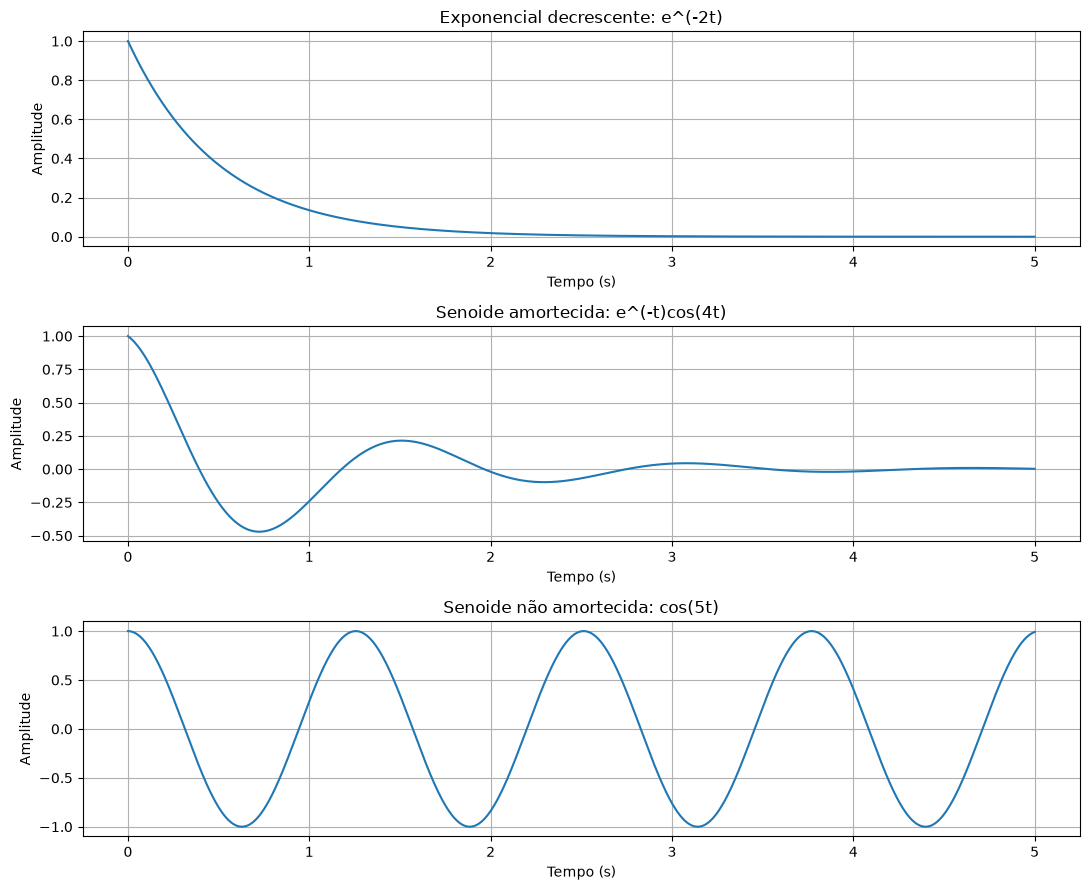

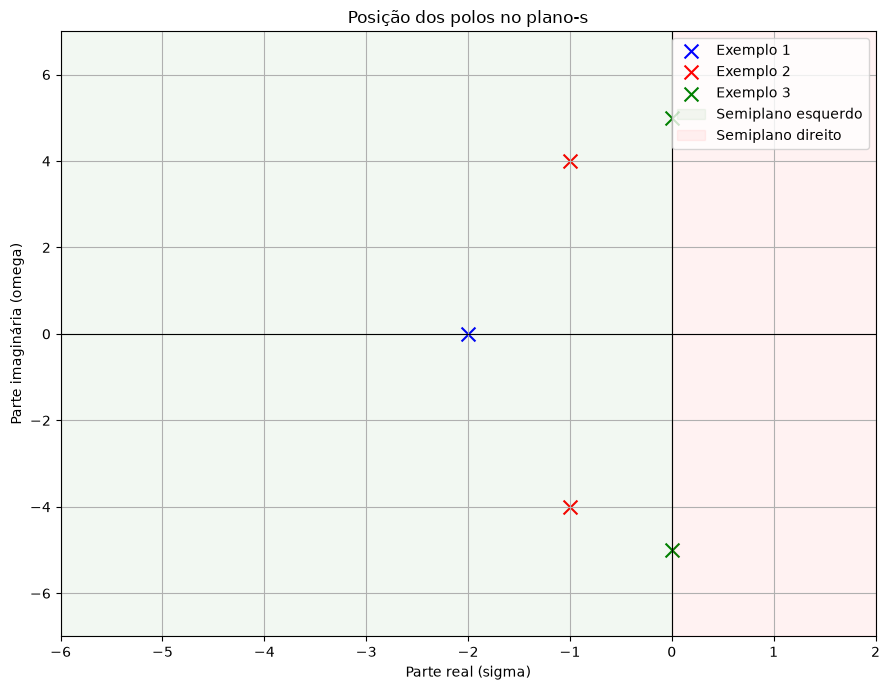

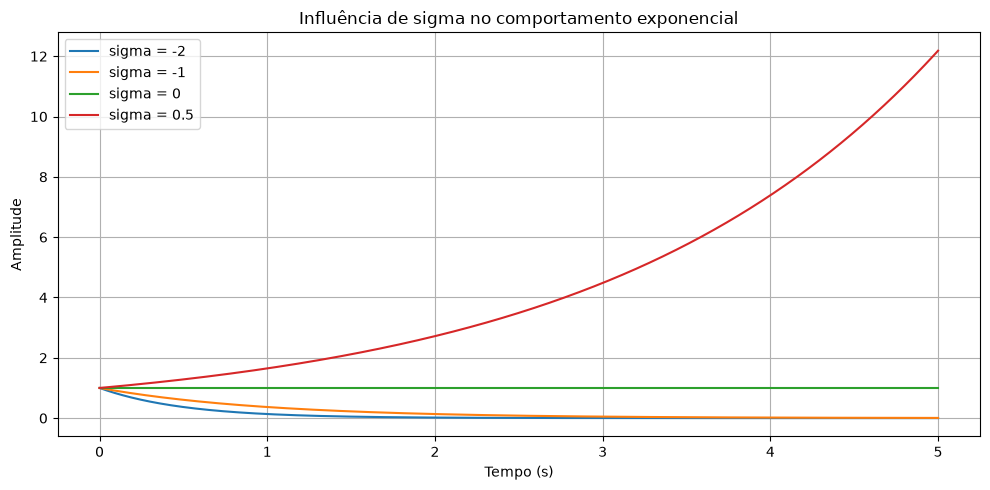

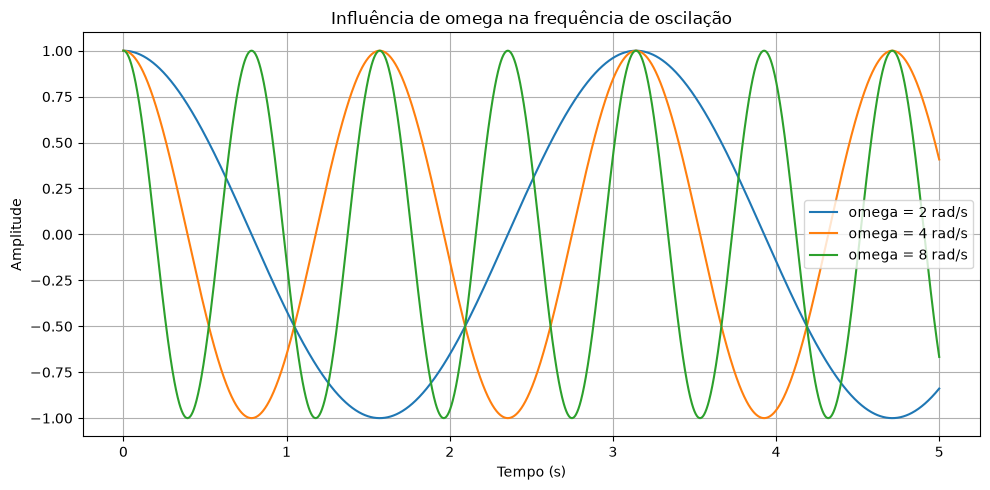

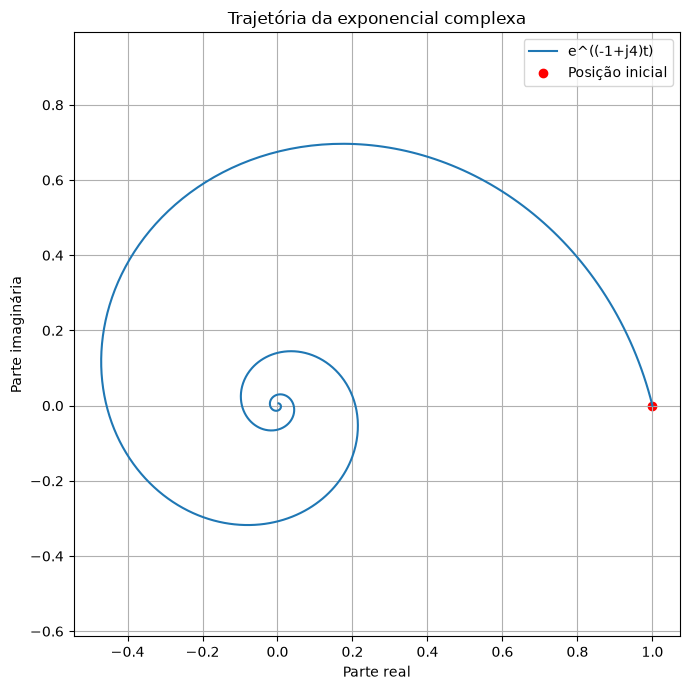


RESUMO DOS EXEMPLOS

EXEMPLO 1:
Polo: -2
Comportamento: decaimento exponencial.

EXEMPLO 2:
Polos: -1 + j4 e -1 - j4
Comportamento: oscilação amortecida.

EXEMPLO 3:
Polos: +j5 e -j5
Comportamento: oscilação sem amortecimento.

Simulação concluída!


In [3]:

import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

# ============================================================
# 1. DEFINIÇÕES SIMBÓLICAS
# ============================================================

t, s = sp.symbols('t s', real=True)
sigma, omega = sp.symbols('sigma omega', real=True)

# Degrau unitário
u = sp.Heaviside(t)

# Sinais temporais
x1 = sp.exp(-2*t) * u
x2 = sp.exp(-t) * sp.cos(4*t) * u
x3 = sp.cos(5*t) * u

# Transformadas de Laplace
X1 = sp.laplace_transform(x1, t, s, noconds=True)
X2 = sp.laplace_transform(x2, t, s, noconds=True)
X3 = sp.laplace_transform(x3, t, s, noconds=True)


# ============================================================
# 2. APRESENTAÇÃO DOS RESULTADOS ANALÍTICOS
# ============================================================

print("TRANSFORMADAS DE LAPLACE")
print("=" * 60)

print("\nExemplo 1: Exponencial decrescente")
print("x1(t) =", x1)
print("X1(s) =", sp.simplify(X1))

print("\nExemplo 2: Senoide amortecida")
print("x2(t) =", x2)
print("X2(s) =", sp.simplify(X2))

print("\nExemplo 3: Senoide não amortecida")
print("x3(t) =", x3)
print("X3(s) =", sp.simplify(X3))


# ============================================================
# 3. IDENTIFICAÇÃO DOS POLOS
# ============================================================

polos1 = sp.solve(
    sp.denom(X1),
    s
)

polos2 = sp.solve(
    sp.denom(X2),
    s
)

polos3 = sp.solve(
    sp.denom(X3),
    s
)

print("\nPOLOS DAS TRANSFORMADAS")
print("=" * 60)

print("Exemplo 1:", polos1)
print("Exemplo 2:", polos2)
print("Exemplo 3:", polos3)


# ============================================================
# 4. REPRESENTAÇÃO DOS SINAIS NO DOMÍNIO DO TEMPO
# ============================================================

tempo = np.linspace(0, 5, 2000)

# Respostas temporais
y1 = np.exp(-2 * tempo)
y2 = np.exp(-tempo) * np.cos(4 * tempo)
y3 = np.cos(5 * tempo)

fig, axes = plt.subplots(
    3, 1,
    figsize=(11, 9)
)

sinais = [
    (y1, "Exponencial decrescente: e^(-2t)"),
    (y2, "Senoide amortecida: e^(-t)cos(4t)"),
    (y3, "Senoide não amortecida: cos(5t)")
]

for ax, (sinal, titulo) in zip(axes, sinais):

    ax.plot(tempo, sinal)

    ax.set_title(titulo)
    ax.set_xlabel("Tempo (s)")
    ax.set_ylabel("Amplitude")

    ax.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 5. REPRESENTAÇÃO DOS POLOS NO PLANO-S
# ============================================================

plt.figure(figsize=(9, 7))

# Polos do exemplo 1
plt.scatter(
    [-2],
    [0],
    color="blue",
    marker="x",
    s=100,
    label="Exemplo 1"
)

# Polos do exemplo 2
plt.scatter(
    [-1, -1],
    [4, -4],
    color="red",
    marker="x",
    s=100,
    label="Exemplo 2"
)

# Polos do exemplo 3
plt.scatter(
    [0, 0],
    [5, -5],
    color="green",
    marker="x",
    s=100,
    label="Exemplo 3"
)

# Eixos
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(0, color="black", linewidth=0.8)

# Identificação das regiões
plt.axvspan(
    -6, 0,
    color="green",
    alpha=0.05,
    label="Semiplano esquerdo"
)

plt.axvspan(
    0, 2,
    color="red",
    alpha=0.05,
    label="Semiplano direito"
)

plt.title("Posição dos polos no plano-s")
plt.xlabel("Parte real (sigma)")
plt.ylabel("Parte imaginária (omega)")

plt.xlim(-6, 2)
plt.ylim(-7, 7)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 6. INFLUÊNCIA DA PARTE REAL SIGMA
# ============================================================

tempo = np.linspace(0, 5, 1000)

valores_sigma = [-2, -1, 0, 0.5]

plt.figure(figsize=(10, 5))

for sig in valores_sigma:

    sinal = np.exp(sig * tempo)

    plt.plot(
        tempo,
        sinal,
        label=f"sigma = {sig}"
    )

plt.title("Influência de sigma no comportamento exponencial")
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 7. INFLUÊNCIA DA PARTE IMAGINÁRIA OMEGA
# ============================================================

tempo = np.linspace(0, 5, 2000)

valores_omega = [2, 4, 8]

plt.figure(figsize=(10, 5))

for w in valores_omega:

    sinal = np.cos(w * tempo)

    plt.plot(
        tempo,
        sinal,
        label=f"omega = {w} rad/s"
    )

plt.title("Influência de omega na frequência de oscilação")
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 8. REPRESENTAÇÃO DA EXPONENCIAL COMPLEXA
# ============================================================

# Exemplo: s = -1 + j4
sig = -1
w = 4

tempo = np.linspace(0, 5, 1000)

z = np.exp((sig + 1j*w) * tempo)

plt.figure(figsize=(7, 7))

plt.plot(
    np.real(z),
    np.imag(z),
    label="e^((-1+j4)t)"
)

plt.scatter(
    [1],
    [0],
    color="red",
    label="Posição inicial"
)

plt.title("Trajetória da exponencial complexa")
plt.xlabel("Parte real")
plt.ylabel("Parte imaginária")

plt.axis("equal")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 9. RESUMO DOS PARÂMETROS
# ============================================================

print("\nRESUMO DOS EXEMPLOS")
print("=" * 60)

print("""
EXEMPLO 1:
Polo: -2
Comportamento: decaimento exponencial.

EXEMPLO 2:
Polos: -1 + j4 e -1 - j4
Comportamento: oscilação amortecida.

EXEMPLO 3:
Polos: +j5 e -j5
Comportamento: oscilação sem amortecimento.
""")

print("Simulação concluída!")
